# Log-Gaussian Cox process inference via GP flow matching

A log-Gaussian Cox process (LGCP) is an inhomogeneous Poisson process whose intensity $\lambda(t) = e^{f(t)}$ has a GP prior on the log-intensity $f$:

$$
f \sim \mathcal{GP}(\mu, k), \qquad \{t_i\} \mid f \sim \text{PoissonProcess}\bigl(e^{f}\bigr), \qquad
\log p(\{t_i\} \mid f) = \sum_{i} f(t_i) - \int_0^T e^{f(t)}\, \mathrm{d}t.
$$

We draw samples from the GP prior with a flow and guide them towards the posterior $p(f \mid \{t_i\})$ using likelihood gradients. Two discretisations of the likelihood are compared: counting events per grid bin, and interpolating $f$ at the exact event times.

## 1. Setup

`TRUE_*` are the data-generating GP parameters, which we reuse for the prior; in practice they would be estimated from the data.

In [1]:
import gpytorch
import matplotlib.pyplot as plt
import numpy as np
import torch

from flow_inference.conditions import BaseCondition
from flow_inference.flow_utils import build_grid_in_box
from flow_inference.flows import GaussianProcessFlow
from flow_inference.guidance import GuidanceMC
from flow_inference.sampler import IntegratorSampler

torch.set_default_dtype(torch.float64)

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

SEED = 1066 if device == "cuda" else 42  # chosen for a clear visual example
T = 10.0            # observation window [0, T]
N = 256             # inference grid points
N_TRUTH = 2000      # fine grid for simulating the ground truth
NUM_SAMPLES = 100
NUM_STEPS = 500

TRUE_LENGTHSCALE = 1.0
TRUE_OUTPUTSCALE = 10.0
TRUE_MEAN = 1.0

## 2. Simulated data

Draw $f^*$ from the GP on a fine grid and simulate events by Lewis–Shedler thinning: propose candidates from a homogeneous Poisson process at rate $\lambda_{\max}$ and accept each at $t$ with probability $\lambda^*(t)/\lambda_{\max}$.

In [3]:
torch.manual_seed(SEED)
t_truth = torch.linspace(0.0, T, N_TRUTH, device=device)

kernel_true = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel()).to(device)
kernel_true.base_kernel.lengthscale = TRUE_LENGTHSCALE
kernel_true.outputscale = TRUE_OUTPUTSCALE

with torch.no_grad():
    K_truth = kernel_true(t_truth.unsqueeze(-1)).evaluate()
    L_truth = torch.linalg.cholesky(K_truth + 1e-6 * torch.eye(N_TRUTH, device=device))
    f_truth = TRUE_MEAN + L_truth @ torch.randn(N_TRUTH, device=device)
lambda_truth = torch.exp(f_truth)

# Lewis-Shedler thinning, with lambda* linearly interpolated at each candidate
lambda_max = lambda_truth.max().item()
dt_truth = T / N_TRUTH
n_candidates = torch.poisson(torch.tensor(lambda_max * T)).long().item()
t_candidates = torch.rand(n_candidates, device=device) * T

idx_lo = (t_candidates / dt_truth).long().clamp(0, N_TRUTH - 2)
frac = (t_candidates / dt_truth) - idx_lo.float()
lam_at_candidates = (1 - frac) * lambda_truth[idx_lo] + frac * lambda_truth[idx_lo + 1]

accept = torch.rand(n_candidates, device=device) < lam_at_candidates / lambda_max
t_events = t_candidates[accept].sort().values

print(f"Expected events: {(lambda_truth.mean() * T).item():.1f}, observed: {len(t_events)}")

Expected events: 571.6, observed: 528


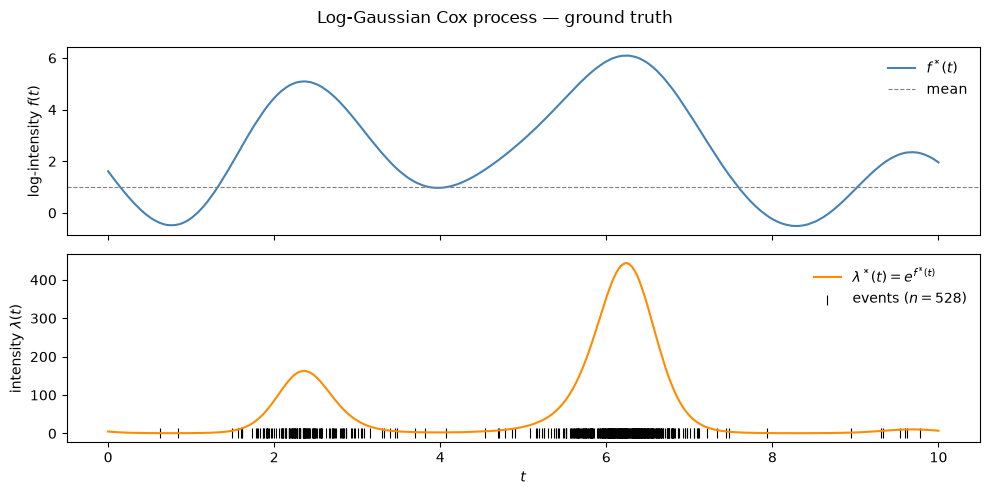

In [4]:
t_np = t_truth.cpu().numpy()
f_np = f_truth.cpu().numpy()
lam_np = lambda_truth.cpu().numpy()
ev_np = t_events.cpu().numpy()

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(t_np, f_np, color="steelblue", lw=1.5, label="$f^*(t)$")
axes[0].axhline(TRUE_MEAN, color="gray", lw=0.8, ls="--", label="mean")
axes[0].set_ylabel("log-intensity $f(t)$")
axes[0].legend(frameon=False)

axes[1].plot(t_np, lam_np, color="darkorange", lw=1.5, label="$\\lambda^*(t) = e^{f^*(t)}$")
axes[1].scatter(ev_np, np.zeros(len(ev_np)), marker="|", color="black",
                s=60, linewidths=0.8, label=f"events ($n={len(ev_np)}$)")
axes[1].set_xlabel("$t$")
axes[1].set_ylabel("intensity $\\lambda(t)$")
axes[1].legend(frameon=False)

fig.suptitle("Log-Gaussian Cox process — ground truth", fontsize=12)
plt.tight_layout()
plt.show()

## 3. GP prior and sampler

Both likelihoods share the same prior flow on an $N$-point grid. `build_grid_in_box` returns coordinates in $[0, 1)$, so the lengthscale is divided by $T$.

In [5]:
coords = build_grid_in_box(N, 1, device)  # (N, 1)

kernel_prior = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel()).to(device)
kernel_prior.base_kernel.lengthscale = TRUE_LENGTHSCALE / T
kernel_prior.outputscale = TRUE_OUTPUTSCALE

prior_mean = gpytorch.means.ConstantMean().to(device)
with torch.no_grad():
    prior_mean.constant.fill_(TRUE_MEAN)

flow = GaussianProcessFlow(kernel_prior, prior_mean, coords, device=device)
sampler = IntegratorSampler(flow=flow)

t_infer = coords.squeeze(-1).cpu().numpy() * T  # grid in original time units

In [6]:
def plot_posterior(samples, title=""):
    # Posterior mean and 90% interval of f and exp(f) against the truth
    samples_f = samples.squeeze(1).cpu().numpy()  # (B, N)
    post_mean = samples_f.mean(axis=0)
    post_lo = np.quantile(samples_f, 0.05, axis=0)
    post_hi = np.quantile(samples_f, 0.95, axis=0)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    axes[0].plot(t_np, f_np, "k-", lw=2, label="$f^*$ (truth)", zorder=4)
    axes[0].fill_between(t_infer, post_lo, post_hi, color="steelblue", alpha=0.3, label="90% CI")
    axes[0].plot(t_infer, post_mean, color="steelblue", lw=1.5, label="posterior mean")
    axes[0].set_ylabel("log-intensity $f(t)$")
    axes[0].legend(frameon=False)

    axes[1].plot(t_np, lam_np, "k-", lw=2, label="$\\lambda^*$ (truth)", zorder=4)
    axes[1].fill_between(t_infer, np.exp(post_lo), np.exp(post_hi), color="darkorange", alpha=0.3, label="90% CI")
    axes[1].plot(t_infer, np.exp(post_mean), color="darkorange", lw=1.5, label="posterior mean")
    axes[1].scatter(ev_np, np.zeros(len(ev_np)), marker="|", color="black",
                    s=60, linewidths=0.8, label=f"events ($n={len(ev_np)}$)")
    axes[1].set_xlabel("$t$")
    axes[1].set_ylabel("intensity $\\lambda(t)$")
    axes[1].legend(frameon=False)

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

## 4. Binned likelihood

Bin the events into the $N$ grid cells. Cell $j$ has count $n_j$ and Poisson mean $e^{f_j}\Delta t$:

$$
\log p(\{n_j\} \mid f) = \sum_{j} \bigl[ n_j f_j - e^{f_j} \Delta t \bigr].
$$

With $N = 256$, the bin width $\Delta t = T/N \approx 0.04$ is much shorter than the lengthscale of $f$, so the binning error is small.

In [7]:
class BinnedPoissonCondition(BaseCondition):
    def __init__(self, event_counts: torch.Tensor, T: float):
        super().__init__()
        self.register_buffer("n", event_counts)
        self.register_buffer("dt", torch.tensor(T / len(event_counts)))

    def logp(self, x: torch.Tensor) -> torch.Tensor:
        f = x.squeeze(1)
        return (self.n * f - self.dt * torch.exp(f)).sum(dim=-1)

  0%|          | 0/499 [00:00<?, ?it/s]

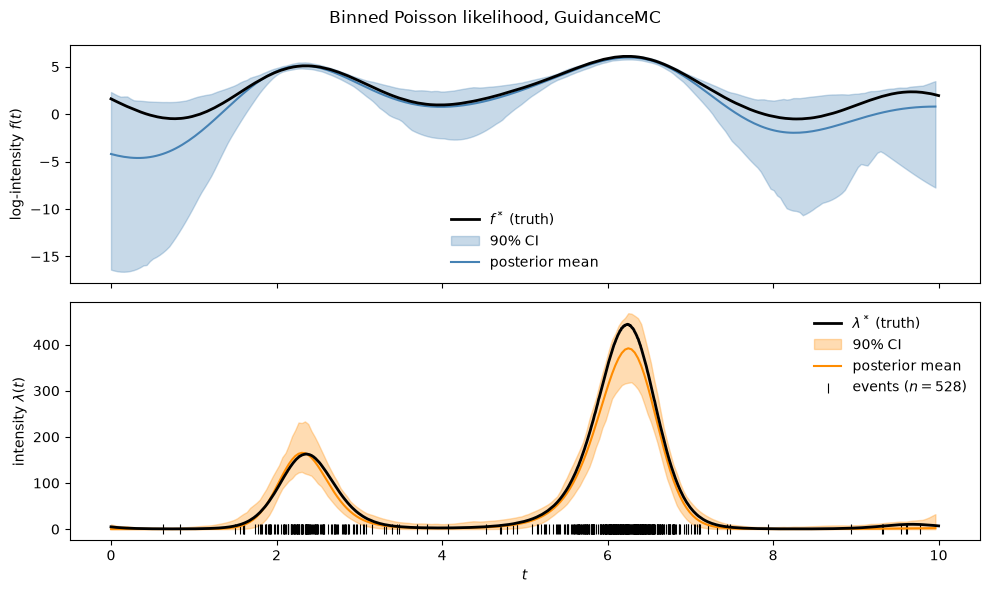

In [8]:
bin_indices = (t_events / T * N).long().clamp(0, N - 1)
event_counts = torch.zeros(N, device=device)
event_counts.scatter_add_(0, bin_indices, torch.ones(len(bin_indices), device=device))

condition = BinnedPoissonCondition(event_counts, T).to(device)
guidance = GuidanceMC(flow, condition, num_mc_samples=1).to(device)

torch.manual_seed(SEED)
samples = sampler.sample(NUM_SAMPLES, guidance=guidance, num_steps=NUM_STEPS, time_schedule="snr")
plot_posterior(samples, title="Binned Poisson likelihood, GuidanceMC")

## 5. Exact likelihood (interpolated)

Evaluate $f$ at each event time $t_i$ by linear interpolation of the grid values, and approximate $\int_0^T e^{f(t)}\,\mathrm{d}t$ by a Riemann sum on the grid. The interpolation weights are precomputed, so `logp` is a cheap gather.

In [9]:
class ExactPoissonCondition(BaseCondition):
    def __init__(self, event_times: torch.Tensor, T: float, N: int):
        super().__init__()
        self.register_buffer("dt", torch.tensor(T / N))

        # Linear interpolation weights of each event onto the grid
        frac_idx = (event_times / T * N).clamp(0.0, N - 1.0 - 1e-9)
        idx_lo = frac_idx.long()
        frac = frac_idx - idx_lo.double()
        self.register_buffer("idx_lo", idx_lo)
        self.register_buffer("w_lo", 1.0 - frac)
        self.register_buffer("w_hi", frac)

    def logp(self, x: torch.Tensor) -> torch.Tensor:
        f = x.squeeze(1)  # (B, N)
        f_at_events = self.w_lo * f[:, self.idx_lo] + self.w_hi * f[:, self.idx_lo + 1]
        event_term = f_at_events.sum(dim=-1)
        integral = self.dt * torch.exp(f).sum(dim=-1)
        return event_term - integral

  0%|          | 0/499 [00:00<?, ?it/s]

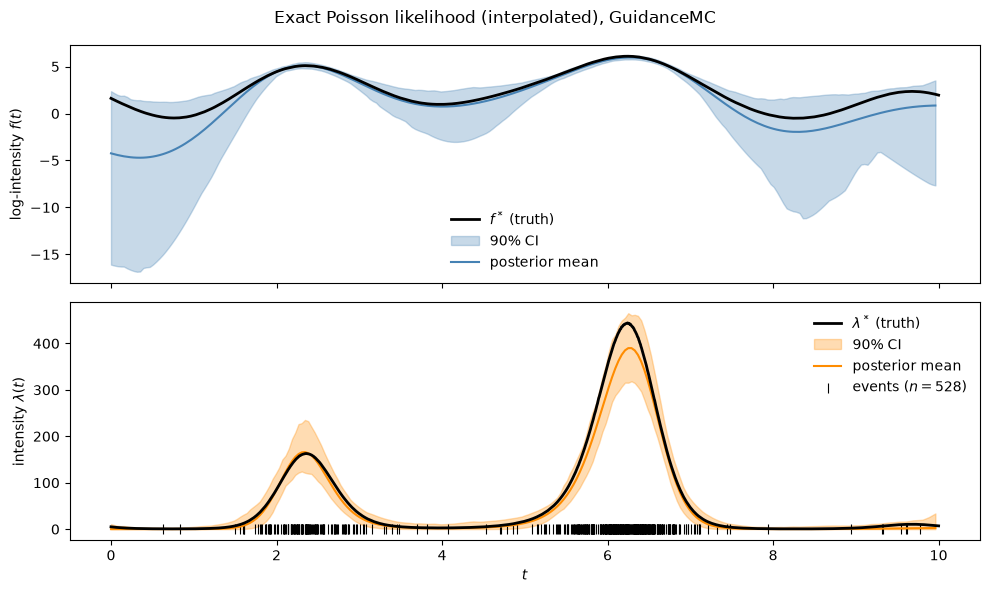

In [10]:
condition = ExactPoissonCondition(t_events, T, N).to(device)
guidance = GuidanceMC(flow, condition, num_mc_samples=1).to(device)

torch.manual_seed(SEED)
samples = sampler.sample(NUM_SAMPLES, guidance=guidance, num_steps=NUM_STEPS, time_schedule="snr")
plot_posterior(samples, title="Exact Poisson likelihood (interpolated), GuidanceMC")